# Best Players in the WNBA

(https://www.espn.com/wnba/story/_/id/40104665/wnba-2024-top-25-best-players-preseason-ranking)



A'ja Wilson – 2018 (1st overall) → Las Vegas Aces

Napheesa Collier – 2019 (6th overall) → Minnesota Lynx

Breanna Stewart – 2016 (1st overall) → Seattle Storm, New York Liberty

Alyssa Thomas – 2014 (4th overall) → Connecticut Sun

Caitlin Clark – 2024 (1st overall) → Indiana Fever

Nneka Ogwumike – 2012 (1st overall) → Los Angeles Sparks

Sabrina Ionescu – 2020 (1st overall) → New York Liberty

Jonquel Jones – 2016 (6th overall) → Connecticut Sun, New York Liberty

Jackie Young – 2019 (1st overall) → Las Vegas Aces

Kelsey Plum – 2017 (1st overall) → San Antonio Stars / Las Vegas Aces

Kahleah Copper – 2016 (7th overall) → Washington Mystics, Chicago Sky

Brionna Jones – 2017 (8th overall) → Connecticut Sun

Kelsey Mitchell – 2018 (2nd overall) → Indiana Fever

Kayla McBride – 2014 (3rd overall) → San Antonio Stars / Las Vegas Aces, Minnesota Lynx

Brittney Griner – 2013 (1st overall) → Phoenix Mercury

Jewell Loyd – 2015 (1st overall) → Seattle Storm

Ezi Magbegor – 2019 (12th overall) → Seattle Storm

Skylar Diggins-Smith – 2013 (3rd overall) → Tulsa Shock / Dallas Wings, Phoenix Mercury, Seattle Storm

Marina Mabrey – 2019 (19th overall) → Los Angeles Sparks, Dallas Wings, Chicago Sky

Aliyah Boston – 2023 (1st overall) → Indiana Fever

Alanna Smith – 2019 (8th overall) → Phoenix Mercury, Chicago Sky, Minnesota Lynx

Rhyne Howard – 2022 (1st overall) → Atlanta Dream

DeWanna Bonner – 2009 (5th overall) → Phoenix Mercury, Connecticut Sun

Tina Charles – 2010 (1st overall) → Connecticut Sun, New York Liberty, Washington Mystics, Phoenix Mercury, Seattle Storm

Allisha Gray – 2017 (4th overall) → Dallas Wings, Atlanta Dream

2024 Playoff Teams:


1. New York Liberty
2. Atlanta Dream
3. Las Vegas Aces
4. Seattle Storm
5. Minnesota Lynx
6. Phoenix Mercury
7. Connecticut Sun
8. Indiana Fever



1. New York Liberty

Breanna Stewart – 2023 (1st overall; free agency)

Sabrina Ionescu – 2020 (1st overall; drafted)

Jonquel Jones – 2023 (6th overall; traded)

2. Atlanta Dream

Rhyne Howard – 2022 (1st overall; drafted)

Allisha Gray – 2023 (4th overall; traded)

3. Las Vegas Aces

A'ja Wilson – 2018 (1st overall; drafted)

Jackie Young – 2019 (1st overall; drafted)

Kelsey Plum – 2017 (1st overall; drafted)

Kayla McBride – 2014 (3rd overall; drafted)

4. Seattle Storm

Breanna Stewart – 2016 (1st overall; drafted)

Jewell Loyd – 2015 (1st overall; drafted)

Ezi Magbegor – 2019 (12th overall; drafted)

Tina Charles – 2010 (1st overall; free agency (joined after leaving the Phoenix Mercury midway through the season))

5. Minnesota Lynx

Napheesa Collier – 2019 (6th overall; drafted)

Kayla McBride – 2021 (3rd overall; free agency)

Alanna Smith – 2024 (8th overall; free agency)

6. Phoenix Mercury

Brittney Griner – 2013 (1st overall; drafted)

Skylar Diggins-Smith – 2020 (3rd overall; traded)

DeWanna Bonner – 2009 (5th overall; drafted)

Tina Charles – 2010 (1st overall; free agency (left halfway to join Seattle Storm))

Alanna Smith – 2019 (8th overall; drafted)

7. Connecticut Sun

Alyssa Thomas – 2014 (4th overall; traded)

Jonquel Jones – 2016 (6th overall; traded)

Brionna Jones – 2017 (8th overall; drafted)

DeWanna Bonner – 2020 (5th overall; traded)

Tina Charles – 2010 (1st overall; drafted)

8. Indiana Fever

Caitlin Clark – 2024 (1st overall; drafted)

Kelsey Mitchell – 2018 (2nd overall; drafted)


In [171]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import ttest_ind

from google.colab import drive
drive.mount('/content/gdrive')

attendance_df = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [172]:
# Convert Year, Month, and Day into a proper Date column
attendance_df["Date"] = pd.to_datetime(attendance_df[["Year", "Month", "Day"]].astype(str).agg('-'.join, axis=1), errors='coerce')

In [173]:
attendance_df.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance,Date
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284,1997-06-21
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455,1997-06-21
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915,1997-06-21
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102,1997-06-22
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036,1997-06-23


In [174]:
# New York Liberty home games
ny_liberty_games = attendance_df[attendance_df["Home Team"] == "New York Liberty"].copy()

# Define draft dates for New York Liberty
draft_dates_ny = {
    2020: pd.Timestamp("2020-04-17"),  # Example draft year for New York Liberty
    2023: pd.Timestamp("2023-01-16"),  # Example draft year for New York Liberty
}

# Dictionary to store regression results for New York Liberty
regression_results_ny = {}

# Loop through each draft year for New York Liberty
for year, draft_date in draft_dates_ny.items():
    temp_df = ny_liberty_games.copy()

    # Calculate time trend (t) relative to the current draft date
    temp_df["t"] = (temp_df["Date"] - draft_date).dt.days

    # Create "After" dummy variable (1 = post-draft, 0 = pre-draft)
    temp_df["After"] = (temp_df["t"] >= 0).astype(int)

    # Create interaction term (t * After)
    temp_df["t_After"] = temp_df["t"] * temp_df["After"]

    # Run OLS regression
    model = smf.ols('Attendance ~ t + After + t_After', data=temp_df).fit()

    # Store the model in the regression_results_ny dictionary
    regression_results_ny[year] = model

    # Print results for each year
    print(f"\n===== Regression Results for Draft Year {year} =====")
    print(model.summary())

# Initialize lists to store the results for each draft year
variables = ['t', 'After', 't_After']
results_dict_ny = {'Variable': variables}

# Extract the regression results directly from the fitted model for New York Liberty
for year, model in regression_results_ny.items():
    coefficients = model.params[variables]
    std_errors = model.bse[variables]
    t_values = model.tvalues[variables]
    p_values = model.pvalues[variables]

    results_dict_ny[f'Year {year} Coefficient'] = coefficients
    results_dict_ny[f'Year {year} Std. Error'] = std_errors
    results_dict_ny[f'Year {year} t-value'] = t_values
    results_dict_ny[f'Year {year} p-value'] = p_values

# Convert the dictionary to a DataFrame for display
results_df_ny = pd.DataFrame(results_dict_ny)

# Remove the 'Variable' column
results_df_ny = results_df_ny.drop(columns=['Variable'])

# Display the results for New York Liberty
results_df_ny


===== Regression Results for Draft Year 2020 =====
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.552
Model:                            OLS   Adj. R-squared:                  0.550
Method:                 Least Squares   F-statistic:                     205.1
Date:                Fri, 18 Apr 2025   Prob (F-statistic):           1.17e-86
Time:                        06:37:00   Log-Likelihood:                -4718.9
No. Observations:                 503   AIC:                             9446.
Df Residuals:                     499   BIC:                             9463.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


,Year 2020 Coefficient,Year 2020 Std. Error,Year 2020 t-value,Year 2020 p-value,Year 2023 Coefficient,Year 2023 Std. Error,Year 2023 t-value,Year 2023 p-value
t,-1.187035,0.059314,-20.012811,7.560880e-66,-1.205481,0.052406,-23.002773,2.325192e-80
After,-8086.261405,933.849845,-8.659060,6.615067e-17,2105.489457,958.257175,2.197207,2.846458e-02
t_After,11.432168,0.759962,15.043075,1.912094e-42,14.677420,2.127991,6.897312,1.610790e-11


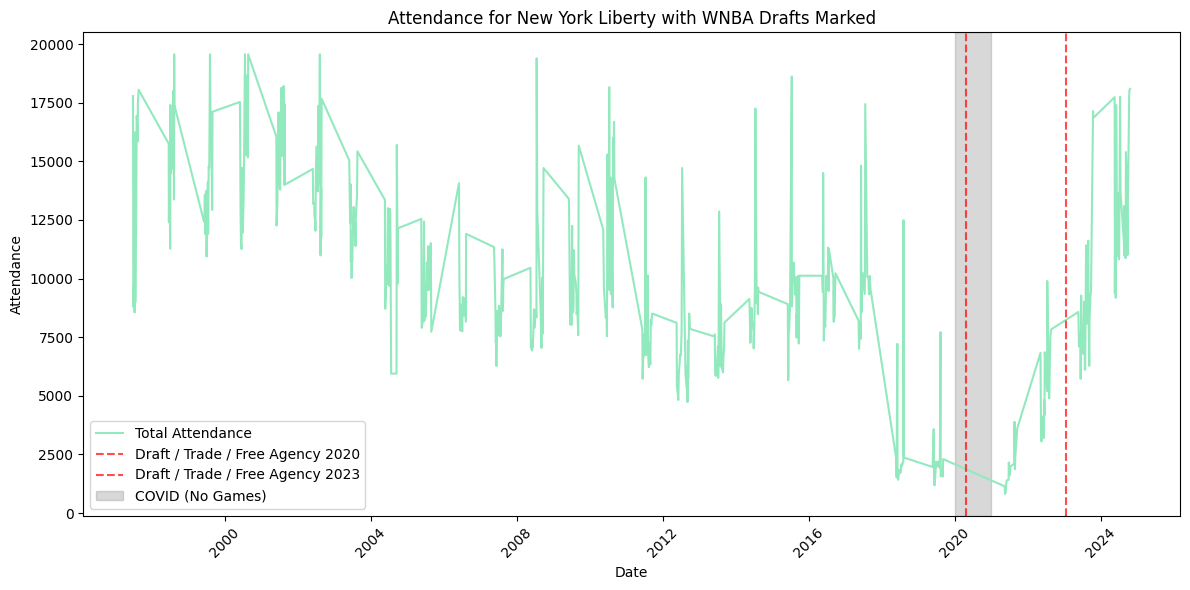

In [175]:
# New York Liberty Visualization
plt.figure(figsize=(12, 6))

# Plot total attendance over time
sns.lineplot(x=ny_liberty_games["Date"], y=ny_liberty_games["Attendance"], label="Total Attendance", color="#93E9BE")

# Mark WNBA Draft dates with vertical dashed lines
for year, draft_date in draft_dates_ny.items():
    plt.axvline(draft_date, linestyle="--", color="red", alpha=0.7, label=f"Draft / Trade / Free Agency {year}")

# Shade the COVID-affected period (2020) when no games were played
plt.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color="gray", alpha=0.3, label="COVID (No Games)")

# Titles and labels
plt.title("Attendance for New York Liberty with WNBA Drafts Marked")
plt.xlabel("Date")
plt.ylabel("Attendance")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [176]:
# Atlanta Dream home games
at_dream_games = attendance_df[attendance_df["Home Team"] == "Atlanta Dream"].copy()

# Define WNBA Draft Dates (Adjust if needed)
draft_dates = {
    2022: pd.Timestamp("2022-04-11"),
    2017: pd.Timestamp("2017-04-13"),
}

# Dictionary to store regression results for Atlanta Dream
regression_results = {}

# Loop through each draft year for Atlanta Dream
for year, draft_date in draft_dates.items():
    temp_df = at_dream_games.copy()

    # Calculate time trend (t) relative to the current draft date
    temp_df["t"] = (temp_df["Date"] - draft_date).dt.days

    # Create "After" dummy variable (1 = post-draft, 0 = pre-draft)
    temp_df["After"] = (temp_df["t"] >= 0).astype(int)

    # Create interaction term (t * After)
    temp_df["t_After"] = temp_df["t"] * temp_df["After"]

    # Run OLS regression
    model = smf.ols('Attendance ~ t + After + t_After', data=temp_df).fit()

    # Store model summary in dictionary
    regression_results[year] = model

    # Print results for each year
    print(f"\n===== Regression Results for Draft Year {year} =====")
    print(model.summary())

# Initialize lists to store the results for each draft year
variables = ['t', 'After', 't_After']
results_dict = {'Variable': variables}

# Extract the regression results directly from the fitted model for Atlanta Dream
for year, model in regression_results.items():
    coefficients = model.params[variables]
    std_errors = model.bse[variables]
    t_values = model.tvalues[variables]
    p_values = model.pvalues[variables]

    results_dict[f'Year {year} Coefficient'] = coefficients
    results_dict[f'Year {year} Std. Error'] = std_errors
    results_dict[f'Year {year} t-value'] = t_values
    results_dict[f'Year {year} p-value'] = p_values

# Convert the dictionary to a DataFrame for display
results_df = pd.DataFrame(results_dict)

# Remove the 'Variable' column
results_df = results_df.drop(columns=['Variable'])

# Display the results for Atlanta Dream
results_df


===== Regression Results for Draft Year 2022 =====
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.430
Model:                            OLS   Adj. R-squared:                  0.424
Method:                 Least Squares   F-statistic:                     73.41
Date:                Fri, 18 Apr 2025   Prob (F-statistic):           2.09e-35
Time:                        06:37:01   Log-Likelihood:                -2647.3
No. Observations:                 296   AIC:                             5303.
Df Residuals:                     292   BIC:                             5317.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


,Year 2022 Coefficient,Year 2022 Std. Error,Year 2022 t-value,Year 2022 p-value,Year 2017 Coefficient,Year 2017 Std. Error,Year 2017 t-value,Year 2017 p-value
t,-1.073780,0.08739,-12.287276,2.978680e-28,-0.823509,0.162223,-5.076410,6.861604e-07
After,-314.132924,525.97779,-0.597236,5.508126e-01,-948.664066,451.660413,-2.100392,3.655185e-02
t_After,3.816752,0.80408,4.746732,3.242307e-06,0.516482,0.249902,2.066739,3.964006e-02


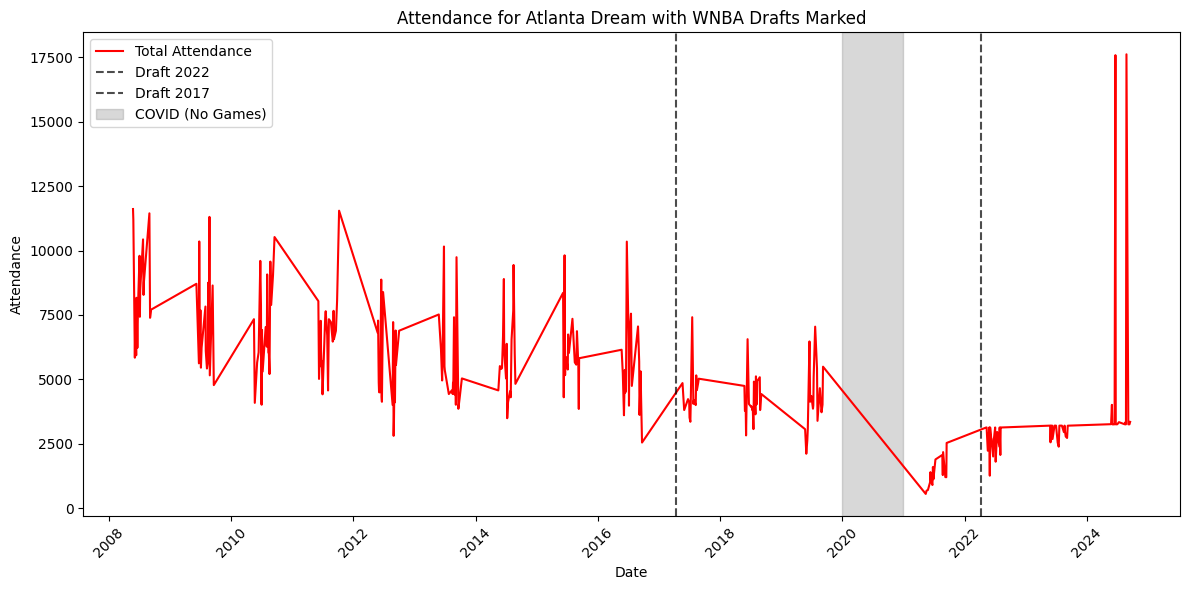

In [177]:
# Atlanta Dream Visualization

plt.figure(figsize=(12, 6))

# Plot total attendance over time
sns.lineplot(x=at_dream_games["Date"], y=at_dream_games["Attendance"], label="Total Attendance", color="red")

# Mark WNBA Draft dates with vertical dashed lines
for year, draft_date in draft_dates.items():
    plt.axvline(draft_date, linestyle="--", color="black", alpha=0.7, label=f"Draft {year}")

# Shade the COVID-affected period (2020) when no games were played
plt.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color="gray", alpha=0.3, label="COVID (No Games)")

# Titles and labels
plt.title("Attendance for Atlanta Dream with WNBA Drafts Marked")
plt.xlabel("Date")
plt.ylabel("Attendance")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [178]:
# Las Vegas Aces (including former teams)
former_aces = ["Utah Starzz", "San Antonio Silver Stars", "San Antonio Stars", "Las Vegas Aces"]
lv_aces_games = attendance_df[attendance_df["Home Team"].isin(former_aces)].copy()

# Define WNBA Draft Dates (Adjust if needed)
draft_dates = {
    2018: pd.Timestamp("2018-04-12"), # Las Vegas Aces
    2017: pd.Timestamp("2017-04-13"), # San Antonio Stars
    2016: pd.Timestamp("2016-04-14"), # San Antonio Stars
    2014: pd.Timestamp("2014-04-14")  # San Antonio Silver Stars
}

# Dictionary to store regression results for Las Vegas Aces
regression_results = {}

# Loop through each draft year for Las Vegas Aces
for year, draft_date in draft_dates.items():
    temp_df = lv_aces_games.copy()

    # Calculate time trend (t) relative to the current draft date
    temp_df["t"] = (temp_df["Date"] - draft_date).dt.days

    # Create "After" dummy variable (1 = post-draft, 0 = pre-draft)
    temp_df["After"] = (temp_df["t"] >= 0).astype(int)

    # Create interaction term (t * After)
    temp_df["t_After"] = temp_df["t"] * temp_df["After"]

    # Run OLS regression
    model = smf.ols('Attendance ~ t + After + t_After', data=temp_df).fit()

    # Store model summary in dictionary
    regression_results[year] = model

    # Print results for each year
    print(f"\n===== Regression Results for Draft Year {year} =====")
    print(model.summary())

# Initialize lists to store the results for each draft year
variables = ['t', 'After', 't_After']
results_dict = {'Variable': variables}

# Extract the regression results directly from the fitted model for Las Vegas Aces
for year, model in regression_results.items():
    coefficients = model.params[variables]
    std_errors = model.bse[variables]
    t_values = model.tvalues[variables]
    p_values = model.pvalues[variables]

    results_dict[f'Year {year} Coefficient'] = coefficients
    results_dict[f'Year {year} Std. Error'] = std_errors
    results_dict[f'Year {year} t-value'] = t_values
    results_dict[f'Year {year} p-value'] = p_values

# Convert the dictionary to a DataFrame for display
results_df = pd.DataFrame(results_dict)

# Remove the 'Variable' column
results_df = results_df.drop(columns=['Variable'])

# Display the results for Las Vegas Aces
results_df


===== Regression Results for Draft Year 2018 =====
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.208
Model:                            OLS   Adj. R-squared:                  0.203
Method:                 Least Squares   F-statistic:                     42.91
Date:                Fri, 18 Apr 2025   Prob (F-statistic):           1.21e-24
Time:                        06:37:02   Log-Likelihood:                -4539.8
No. Observations:                 495   AIC:                             9088.
Df Residuals:                     491   BIC:                             9104.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


,Year 2018 Coefficient,Year 2018 Std. Error,Year 2018 t-value,Year 2018 p-value,Year 2017 Coefficient,Year 2017 Std. Error,Year 2017 t-value,Year 2017 p-value,Year 2016 Coefficient,Year 2016 Std. Error,Year 2016 t-value,Year 2016 p-value,Year 2014 Coefficient,Year 2014 Std. Error,Year 2014 t-value,Year 2014 p-value
t,-0.159196,0.056838,-2.800897,5.297124e-03,-0.130244,0.062684,-2.077793,3.824746e-02,-0.089371,0.068530,-1.304113,1.928061e-01,0.072676,0.081521,0.891503,3.730960e-01
After,-3758.301821,488.752584,-7.689579,8.124871e-14,-3271.190757,474.650210,-6.891793,1.697506e-11,-3088.524497,463.739640,-6.660040,7.353056e-11,-3261.190215,445.492562,-7.320415,1.017777e-12
t_After,3.099865,0.276237,11.221767,3.595806e-26,2.224193,0.232390,9.570967,5.184859e-20,1.677508,0.201699,8.316896,8.957243e-16,0.922348,0.163287,5.648619,2.742424e-08


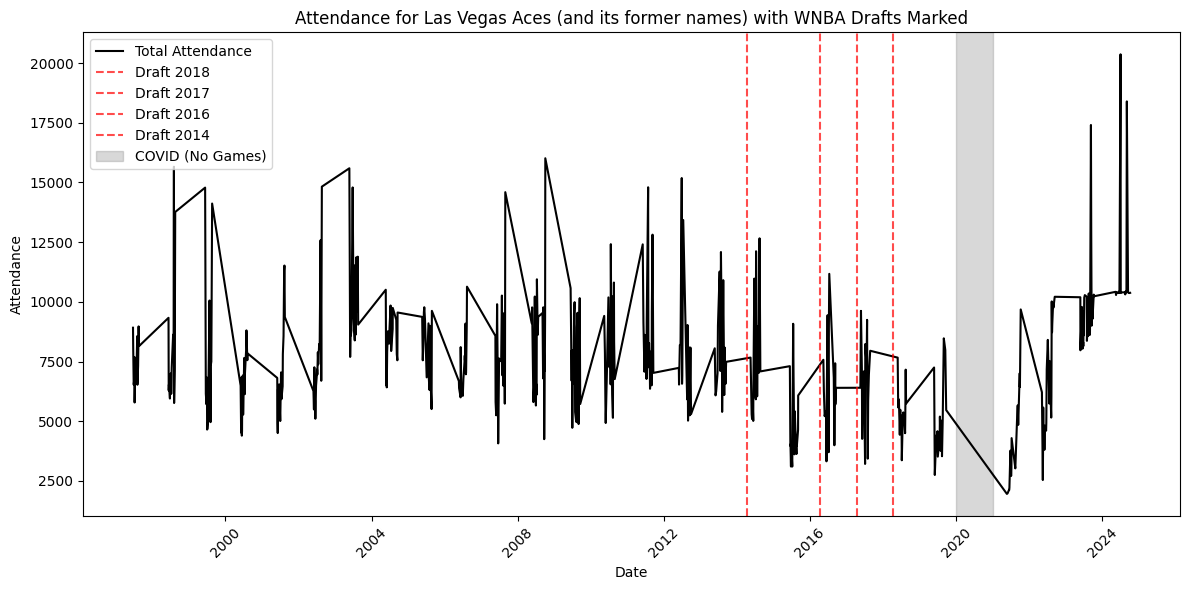

In [179]:
plt.figure(figsize=(12, 6))

# Plot total attendance over time
sns.lineplot(x=lv_aces_games["Date"], y=lv_aces_games["Attendance"], label="Total Attendance", color="black")

# Mark WNBA Draft dates with vertical dashed lines
for year, draft_date in draft_dates.items():
    plt.axvline(draft_date, linestyle="--", color="red", alpha=0.7, label=f"Draft {year}")

# Shade the COVID-affected period (2020) when no games were played
plt.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color="gray", alpha=0.3, label="COVID (No Games)")

# Titles and labels
plt.title("Attendance for Las Vegas Aces (and its former names) with WNBA Drafts Marked")
plt.xlabel("Date")
plt.ylabel("Attendance")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [180]:
# Seattle Storm home games
sea_storm_games = attendance_df[attendance_df["Home Team"] == "Seattle Storm"].copy()

# Define WNBA Draft Dates (Adjust if needed)
draft_dates = {
    2019: pd.Timestamp("2019-04-10"),
    2016: pd.Timestamp("2016-04-14"),
    2015: pd.Timestamp("2015-04-16"),
    2010: pd.Timestamp("2010-04-08")
}

# Dictionary to store regression results for Seattle Storm
regression_results = {}

# Loop through each draft year for Seattle Storm
for year, draft_date in draft_dates.items():
    temp_df = sea_storm_games.copy()

    # Calculate time trend (t) relative to the current draft date
    temp_df["t"] = (temp_df["Date"] - draft_date).dt.days

    # Create "After" dummy variable (1 = post-draft, 0 = pre-draft)
    temp_df["After"] = (temp_df["t"] >= 0).astype(int)

    # Create interaction term (t * After)
    temp_df["t_After"] = temp_df["t"] * temp_df["After"]

    # Run OLS regression
    model = smf.ols('Attendance ~ t + After + t_After', data=temp_df).fit()

    # Store model summary in dictionary
    regression_results[year] = model

    # Print results for each year
    print(f"\n===== Regression Results for Draft Year {year} =====")
    print(model.summary())

# Initialize lists to store the results for each draft year
variables = ['t', 'After', 't_After']
results_dict = {'Variable': variables}

# Extract the regression results directly from the fitted model for Seattle Storm
for year, model in regression_results.items():
    coefficients = model.params[variables]
    std_errors = model.bse[variables]
    t_values = model.tvalues[variables]
    p_values = model.pvalues[variables]

    results_dict[f'Year {year} Coefficient'] = coefficients
    results_dict[f'Year {year} Std. Error'] = std_errors
    results_dict[f'Year {year} t-value'] = t_values
    results_dict[f'Year {year} p-value'] = p_values

# Convert the dictionary to a DataFrame for display
results_df = pd.DataFrame(results_dict)

# Remove the 'Variable' column
results_df = results_df.drop(columns=['Variable'])

# Display the results for Seattle Storm
results_df



===== Regression Results for Draft Year 2019 =====
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.107
Model:                            OLS   Adj. R-squared:                  0.101
Method:                 Least Squares   F-statistic:                     17.53
Date:                Fri, 18 Apr 2025   Prob (F-statistic):           9.09e-11
Time:                        06:37:03   Log-Likelihood:                -4086.8
No. Observations:                 444   AIC:                             8182.
Df Residuals:                     440   BIC:                             8198.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


,Year 2019 Coefficient,Year 2019 Std. Error,Year 2019 t-value,Year 2019 p-value,Year 2016 Coefficient,Year 2016 Std. Error,Year 2016 t-value,Year 2016 p-value,Year 2015 Coefficient,Year 2015 Std. Error,Year 2015 t-value,Year 2015 p-value,Year 2010 Coefficient,Year 2010 Std. Error,Year 2010 t-value,Year 2010 p-value
t,-0.041261,0.065595,-0.629029,5.296563e-01,-0.111849,0.088317,-1.266454,0.206020,-0.034111,0.096531,-0.353373,7.239784e-01,0.277659,0.181247,1.531936,0.126257
After,-2379.069630,581.305100,-4.092635,5.074405e-05,-777.336635,483.670079,-1.607163,0.108736,-1439.419321,473.758713,-3.038296,2.520870e-03,-1271.480020,484.626909,-2.623627,0.009002
t_After,2.777389,0.403035,6.891180,1.925030e-11,1.084351,0.219950,4.929987,0.000001,1.000904,0.197931,5.056841,6.267835e-07,0.013598,0.204760,0.066411,0.947081


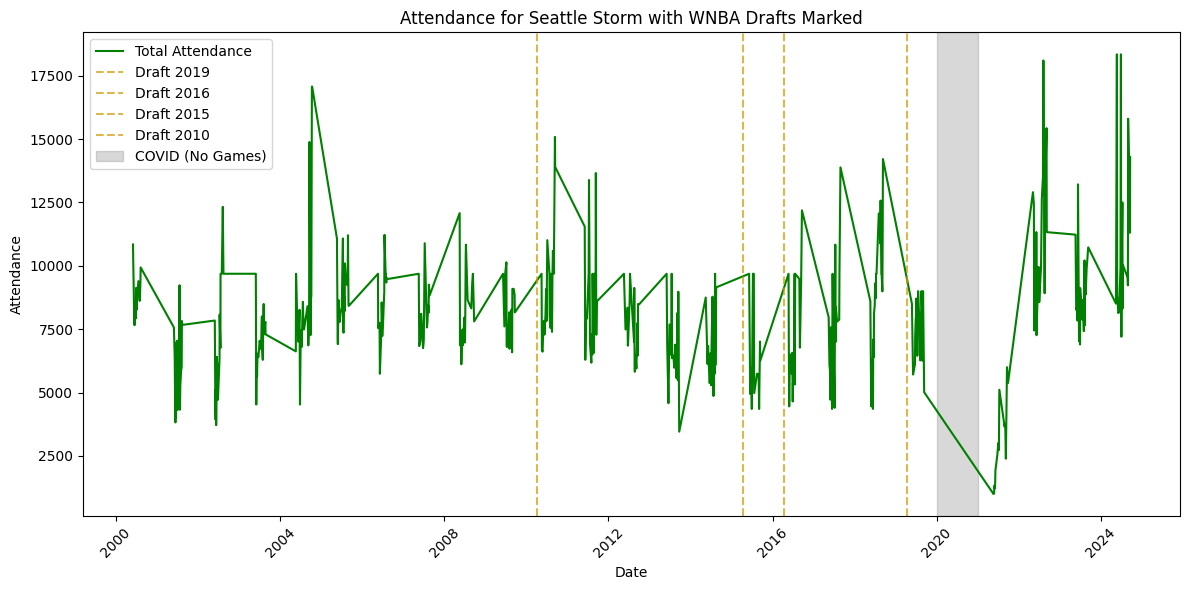

In [181]:
# Seattle Storm Visualization

plt.figure(figsize=(12, 6))

# Plot total attendance over time
sns.lineplot(x=sea_storm_games["Date"], y=sea_storm_games["Attendance"], label="Total Attendance", color="green")

# Mark WNBA Draft dates with vertical dashed lines
for year, draft_date in draft_dates.items():
    plt.axvline(draft_date, linestyle="--", color="#CC9900", alpha=0.7, label=f"Draft {year}")

# Shade the COVID-affected period (2020) when no games were played
plt.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color="gray", alpha=0.3, label="COVID (No Games)")

# Titles and labels
plt.title("Attendance for Seattle Storm with WNBA Drafts Marked")
plt.xlabel("Date")
plt.ylabel("Attendance")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [182]:
# Minnesota Lynx home games
min_lynx_games = attendance_df[attendance_df["Home Team"] == "Minnesota Lynx"].copy()

# Define WNBA Draft Dates (Adjust if needed)
draft_dates = {
    2019: pd.Timestamp("2019-04-10"),
    2016: pd.Timestamp("2014-04-14")
}

# Dictionary to store regression results for Minnesota Lynx
regression_results = {}

# Loop through each draft year for Minnesota Lynx
for year, draft_date in draft_dates.items():
    temp_df = min_lynx_games.copy()

    # Calculate time trend (t) relative to the current draft date
    temp_df["t"] = (temp_df["Date"] - draft_date).dt.days

    # Create "After" dummy variable (1 = post-draft, 0 = pre-draft)
    temp_df["After"] = (temp_df["t"] >= 0).astype(int)

    # Create interaction term (t * After)
    temp_df["t_After"] = temp_df["t"] * temp_df["After"]

    # Run OLS regression
    model = smf.ols('Attendance ~ t + After + t_After', data=temp_df).fit()

    # Store model summary in dictionary
    regression_results[year] = model

    # Print results for each year
    print(f"\n===== Regression Results for Draft Year {year} =====")
    print(model.summary())

# Initialize lists to store the results for each draft year
variables = ['t', 'After', 't_After']
results_dict = {'Variable': variables}

# Extract the regression results directly from the fitted model for Minnesota Lynx
for year, model in regression_results.items():
    coefficients = model.params[variables]
    std_errors = model.bse[variables]
    t_values = model.tvalues[variables]
    p_values = model.pvalues[variables]

    results_dict[f'Year {year} Coefficient'] = coefficients
    results_dict[f'Year {year} Std. Error'] = std_errors
    results_dict[f'Year {year} t-value'] = t_values
    results_dict[f'Year {year} p-value'] = p_values

# Convert the dictionary to a DataFrame for display
results_df = pd.DataFrame(results_dict)

# Remove the 'Variable' column
results_df = results_df.drop(columns=['Variable'])

# Display the results for Minnesota Lynx
results_df


===== Regression Results for Draft Year 2019 =====
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.118
Model:                            OLS   Adj. R-squared:                  0.112
Method:                 Least Squares   F-statistic:                     20.75
Date:                Fri, 18 Apr 2025   Prob (F-statistic):           1.23e-12
Time:                        06:37:03   Log-Likelihood:                -4381.1
No. Observations:                 470   AIC:                             8770.
Df Residuals:                     466   BIC:                             8787.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


,Year 2019 Coefficient,Year 2019 Std. Error,Year 2019 t-value,Year 2019 p-value,Year 2016 Coefficient,Year 2016 Std. Error,Year 2016 t-value,Year 2016 p-value
t,0.450222,0.067293,6.690439,6.397144e-11,0.269765,0.106480,2.533474,0.011621
After,-4060.718493,647.902383,-6.267485,8.364936e-10,1304.731680,489.948707,2.662996,0.008013
t_After,0.869006,0.430957,2.016455,4.432558e-02,-0.869447,0.189708,-4.583072,0.000006


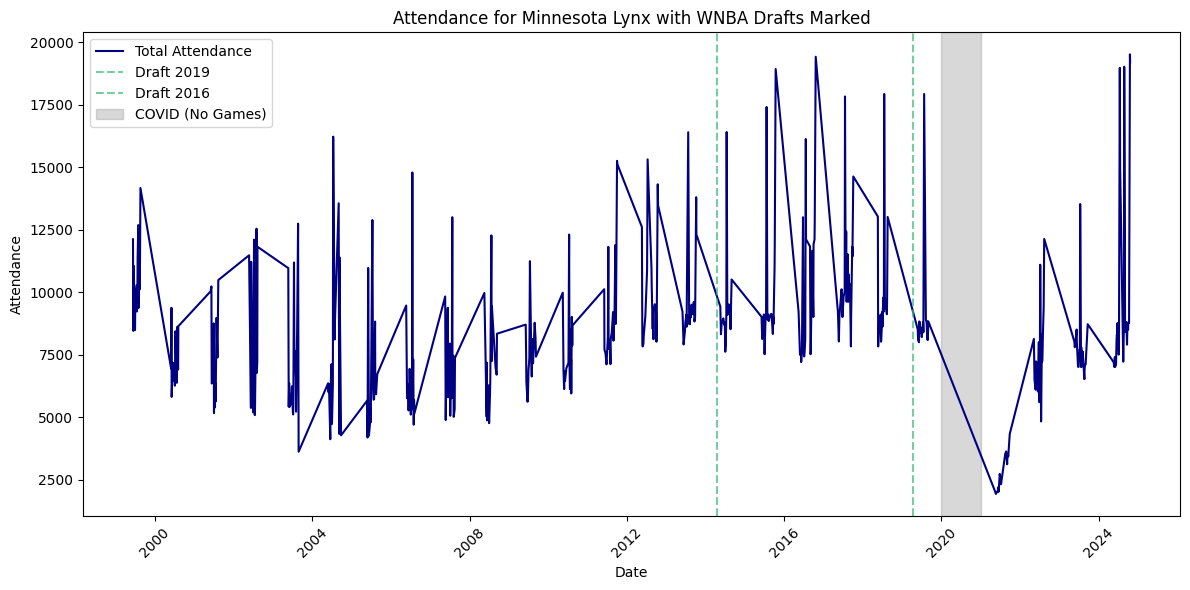

In [183]:
# Minnesota Lynx Visualization

plt.figure(figsize=(12, 6))

# Plot total attendance over time
sns.lineplot(x=min_lynx_games["Date"], y=min_lynx_games["Attendance"], label="Total Attendance", color="#000080")

# Mark WNBA Draft dates with vertical dashed lines
for year, draft_date in draft_dates.items():
    plt.axvline(draft_date, linestyle="--", color="#3CB878", alpha=0.7, label=f"Draft {year}")

# Shade the COVID-affected period (2020) when no games were played
plt.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color="gray", alpha=0.3, label="COVID (No Games)")

# Titles and labels
plt.title("Attendance for Minnesota Lynx with WNBA Drafts Marked")
plt.xlabel("Date")
plt.ylabel("Attendance")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [184]:
# Phoenix Mercury home games
phx_mercury_games = attendance_df[attendance_df["Home Team"] == "Phoenix Mercury"].copy()

# Define WNBA Draft Dates (Adjust if needed)
draft_dates = {
    2019: pd.Timestamp("2019-04-10"),
    2013: pd.Timestamp("2013-04-15"),
    2010: pd.Timestamp("2010-04-08"),
    2009: pd.Timestamp("2009-04-09")
}

# Dictionary to store regression results for Phoenix Mercury
regression_results = {}

# Loop through each draft year for Phoenix Mercury
for year, draft_date in draft_dates.items():
    temp_df = phx_mercury_games.copy()

    # Calculate time trend (t) relative to the current draft date
    temp_df["t"] = (temp_df["Date"] - draft_date).dt.days

    # Create "After" dummy variable (1 = post-draft, 0 = pre-draft)
    temp_df["After"] = (temp_df["t"] >= 0).astype(int)

    # Create interaction term (t * After)
    temp_df["t_After"] = temp_df["t"] * temp_df["After"]

    # Run OLS regression
    model = smf.ols('Attendance ~ t + After + t_After', data=temp_df).fit()

    # Store model summary in dictionary
    regression_results[year] = model

    # Print results for each year
    print(f"\n===== Regression Results for Draft Year {year} =====")
    print(model.summary())

# Initialize lists to store the results for each draft year
variables = ['t', 'After', 't_After']
results_dict = {'Variable': variables}

# Extract the regression results directly from the fitted model for Phoenix Mercury
for year, model in regression_results.items():
    coefficients = model.params[variables]
    std_errors = model.bse[variables]
    t_values = model.tvalues[variables]
    p_values = model.pvalues[variables]

    results_dict[f'Year {year} Coefficient'] = coefficients
    results_dict[f'Year {year} Std. Error'] = std_errors
    results_dict[f'Year {year} t-value'] = t_values
    results_dict[f'Year {year} p-value'] = p_values

# Convert the dictionary to a DataFrame for display
results_df = pd.DataFrame(results_dict)

# Remove the 'Variable' column
results_df = results_df.drop(columns=['Variable'])

# Display the results for Phoenix Mercury
results_df


===== Regression Results for Draft Year 2019 =====
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                     6.245
Date:                Fri, 18 Apr 2025   Prob (F-statistic):           0.000363
Time:                        06:37:04   Log-Likelihood:                -4578.3
No. Observations:                 495   AIC:                             9165.
Df Residuals:                     491   BIC:                             9182.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


,Year 2019 Coefficient,Year 2019 Std. Error,Year 2019 t-value,Year 2019 p-value,Year 2013 Coefficient,Year 2013 Std. Error,Year 2013 t-value,Year 2013 p-value,Year 2010 Coefficient,Year 2010 Std. Error,Year 2010 t-value,Year 2010 p-value,Year 2009 Coefficient,Year 2009 Std. Error,Year 2009 t-value,Year 2009 p-value
t,-0.199511,0.055266,-3.610047,0.000338,-0.745315,0.084979,-8.770616,2.931929e-17,-1.108102,0.111932,-9.899766,3.447747e-21,-1.464521,0.126890,-11.541633,1.973881e-27
After,-503.328083,604.370142,-0.832814,0.405354,2572.991237,415.567108,6.191518,1.259726e-09,2318.530125,408.658798,5.673511,2.393304e-08,2925.246367,408.688391,7.157645,3.009601e-12
t_After,0.879872,0.425321,2.068728,0.039094,0.587099,0.150667,3.896675,1.110528e-04,1.133382,0.143162,7.916796,1.636461e-14,1.492787,0.148566,10.047992,9.963442e-22


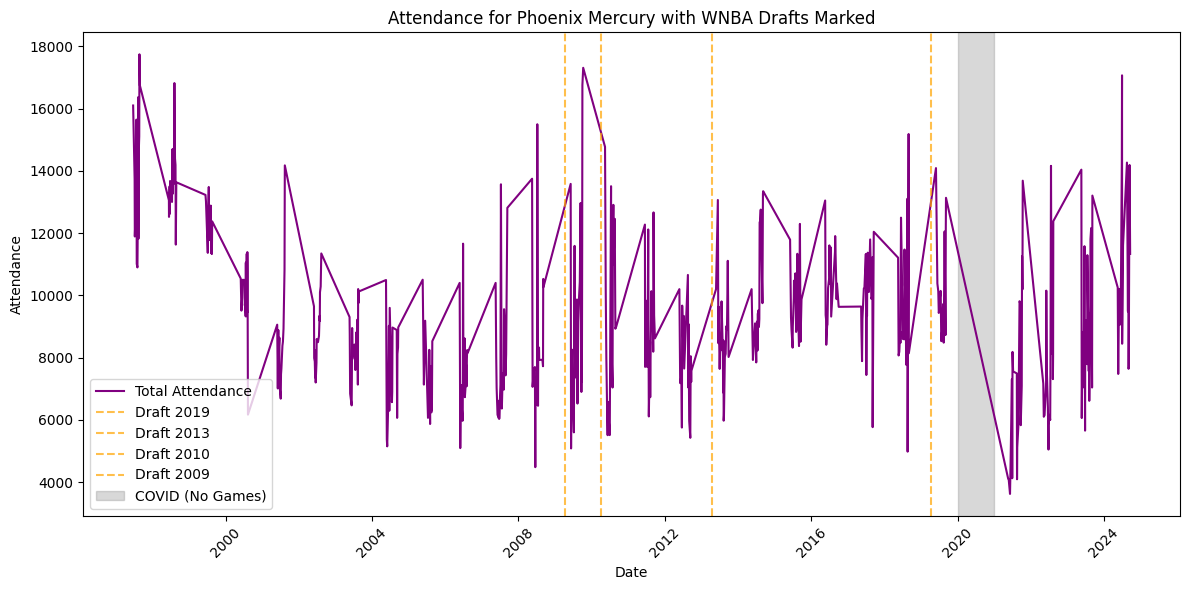

In [185]:
# Phoenix Mercury Visualization

plt.figure(figsize=(12, 6))

# Plot total attendance over time
sns.lineplot(x=phx_mercury_games["Date"], y=phx_mercury_games["Attendance"], label="Total Attendance", color="purple")

# Mark WNBA Draft dates with vertical dashed lines
for year, draft_date in draft_dates.items():
    plt.axvline(draft_date, linestyle="--", color="orange", alpha=0.7, label=f"Draft {year}")

# Shade the COVID-affected period (2020) when no games were played
plt.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color="gray", alpha=0.3, label="COVID (No Games)")

# Titles and labels
plt.title("Attendance for Phoenix Mercury with WNBA Drafts Marked")
plt.xlabel("Date")
plt.ylabel("Attendance")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [186]:
# Connecticut Sun home games
con_sun_games = attendance_df[attendance_df["Home Team"] == "Connecticut Sun"].copy()

# Define WNBA Draft Dates (Adjust if needed)
draft_dates = {
    2017: pd.Timestamp("2017-04-13"),
    2016: pd.Timestamp("2016-04-14"),
    2014: pd.Timestamp("2014-04-14"),
    2010: pd.Timestamp("2010-04-08"),
    2009: pd.Timestamp("2009-04-09")
}

# Dictionary to store regression results for Connecticut Sun
regression_results = {}

# Loop through each draft year for Connecticut Sun
for year, draft_date in draft_dates.items():
    temp_df = con_sun_games.copy()

    # Calculate time trend (t) relative to the current draft date
    temp_df["t"] = (temp_df["Date"] - draft_date).dt.days

    # Create "After" dummy variable (1 = post-draft, 0 = pre-draft)
    temp_df["After"] = (temp_df["t"] >= 0).astype(int)

    # Create interaction term (t * After)
    temp_df["t_After"] = temp_df["t"] * temp_df["After"]

    # Run OLS regression
    model = smf.ols('Attendance ~ t + After + t_After', data=temp_df).fit()

    # Store model summary in dictionary
    regression_results[year] = model

    # Print results for each year
    print(f"\n===== Regression Results for Draft Year {year} =====")
    print(model.summary())

# Initialize lists to store the results for each draft year
variables = ['t', 'After', 't_After']
results_dict = {'Variable': variables}

# Extract the regression results directly from the fitted model for Connecticut Sun
for year, model in regression_results.items():
    coefficients = model.params[variables]
    std_errors = model.bse[variables]
    t_values = model.tvalues[variables]
    p_values = model.pvalues[variables]

    results_dict[f'Year {year} Coefficient'] = coefficients
    results_dict[f'Year {year} Std. Error'] = std_errors
    results_dict[f'Year {year} t-value'] = t_values
    results_dict[f'Year {year} p-value'] = p_values

# Convert the dictionary to a DataFrame for display
results_df = pd.DataFrame(results_dict)

# Remove the 'Variable' column
results_df = results_df.drop(columns=['Variable'])

# Display the results for Connecticut Sun
results_df


===== Regression Results for Draft Year 2017 =====
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.028
Method:                 Least Squares   F-statistic:                     4.934
Date:                Fri, 18 Apr 2025   Prob (F-statistic):            0.00224
Time:                        06:37:05   Log-Likelihood:                -3570.2
No. Observations:                 405   AIC:                             7148.
Df Residuals:                     401   BIC:                             7164.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


,Year 2017 Coefficient,Year 2017 Std. Error,Year 2017 t-value,Year 2017 p-value,Year 2016 Coefficient,Year 2016 Std. Error,Year 2016 t-value,Year 2016 p-value,Year 2014 Coefficient,Year 2014 Std. Error,Year 2014 t-value,Year 2014 p-value,Year 2010 Coefficient,Year 2010 Std. Error,Year 2010 t-value,Year 2010 p-value,Year 2009 Coefficient,Year 2009 Std. Error,Year 2009 t-value,Year 2009 p-value
t,-0.200662,0.069156,-2.901601,0.003917,-0.151886,0.076917,-1.974679,0.048990,0.090453,0.095878,0.943417,0.346036,0.506216,0.195620,2.587755,0.010011,0.934953,0.242149,3.861061,0.000132
After,-152.694254,340.985154,-0.447803,0.654537,-561.579876,333.799691,-1.682386,0.093272,-1555.928690,322.777319,-4.820440,0.000002,-1143.399121,362.304745,-3.155904,0.001721,-1550.561590,374.402313,-4.141432,0.000042
t_After,0.450732,0.166935,2.700052,0.007226,0.439462,0.148931,2.950779,0.003356,0.202425,0.133822,1.512640,0.131159,-0.553831,0.204651,-2.706224,0.007096,-0.989524,0.248180,-3.987116,0.000079


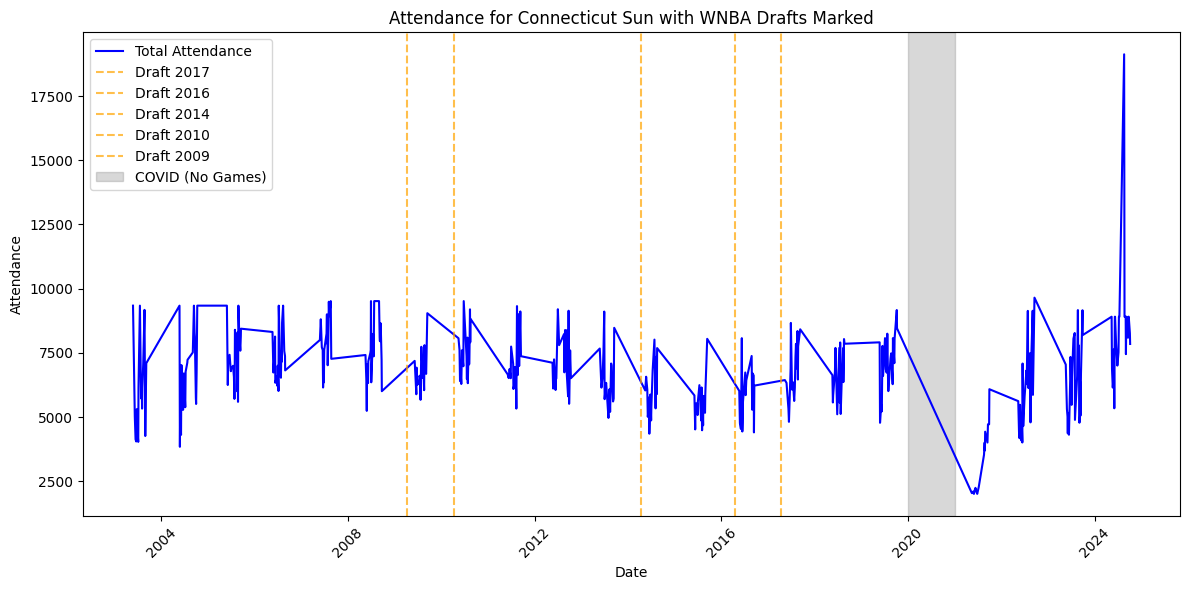

In [187]:
# Connecticut Sun Visualization

plt.figure(figsize=(12, 6))

# Plot total attendance over time
sns.lineplot(x=con_sun_games["Date"], y=con_sun_games["Attendance"], label="Total Attendance", color="blue")

# Mark WNBA Draft dates with vertical dashed lines
for year, draft_date in draft_dates.items():
    plt.axvline(draft_date, linestyle="--", color="orange", alpha=0.7, label=f"Draft {year}")

# Shade the COVID-affected period (2020) when no games were played
plt.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color="gray", alpha=0.3, label="COVID (No Games)")

# Titles and labels
plt.title("Attendance for Connecticut Sun with WNBA Drafts Marked")
plt.xlabel("Date")
plt.ylabel("Attendance")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [190]:
# Indiana Fever home games
ind_fever_games = attendance_df[attendance_df["Home Team"] == "Indiana Fever"].copy()

# Define WNBA Draft Dates (Adjust if needed)
draft_dates = {
    2024: pd.Timestamp("2024-04-15"),
    2018: pd.Timestamp("2018-04-12")
}

# Dictionary to store regression results for Indiana Fever
regression_results = {}

# Loop through each draft year for Indiana Fever
for year, draft_date in draft_dates.items():
    temp_df = ind_fever_games.copy()

    # Calculate time trend (t) relative to the current draft date
    temp_df["t"] = (temp_df["Date"] - draft_date).dt.days

    # Create "After" dummy variable (1 = post-draft, 0 = pre-draft)
    temp_df["After"] = (temp_df["t"] >= 0).astype(int)

    # Create interaction term (t * After)
    temp_df["t_After"] = temp_df["t"] * temp_df["After"]

    # Run OLS regression
    model = smf.ols('Attendance ~ t + After + t_After', data=temp_df).fit()

    # Store model summary in dictionary
    regression_results[year] = model

    # Print results for each year
    print(f"\n===== Regression Results for Draft Year {year} =====")
    print(model.summary())

# Initialize lists to store the results for each draft year
variables = ['t', 'After', 't_After']
results_dict = {'Variable': variables}

# Extract the regression results directly from the fitted model for Indiana Fever
for year, model in regression_results.items():
    coefficients = model.params[variables]
    std_errors = model.bse[variables]
    t_values = model.tvalues[variables]
    p_values = model.pvalues[variables]

    results_dict[f'Year {year} Coefficient'] = coefficients
    results_dict[f'Year {year} Std. Error'] = std_errors
    results_dict[f'Year {year} t-value'] = t_values
    results_dict[f'Year {year} p-value'] = p_values

# Convert the dictionary to a DataFrame for display
results_df = pd.DataFrame(results_dict)

# Remove the 'Variable' column
results_df = results_df.drop(columns=['Variable'])

# Display the results for Indiana Fever
results_df


===== Regression Results for Draft Year 2024 =====
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.519
Model:                            OLS   Adj. R-squared:                  0.516
Method:                 Least Squares   F-statistic:                     152.5
Date:                Fri, 18 Apr 2025   Prob (F-statistic):           4.73e-67
Time:                        06:40:50   Log-Likelihood:                -3913.3
No. Observations:                 428   AIC:                             7835.
Df Residuals:                     424   BIC:                             7851.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


,Year 2024 Coefficient,Year 2024 Std. Error,Year 2024 t-value,Year 2024 p-value,Year 2018 Coefficient,Year 2018 Std. Error,Year 2018 t-value,Year 2018 p-value
t,-0.537242,0.047427,-11.327727,3.624075e-26,-0.160639,0.090574,-1.773571,7.685180e-02
After,11544.823008,1241.092412,9.302146,7.406879e-19,-3956.358955,683.294765,-5.790120,1.370827e-08
t_After,5.025340,11.557257,0.434821,6.639135e-01,2.749915,0.389204,7.065484,6.612015e-12


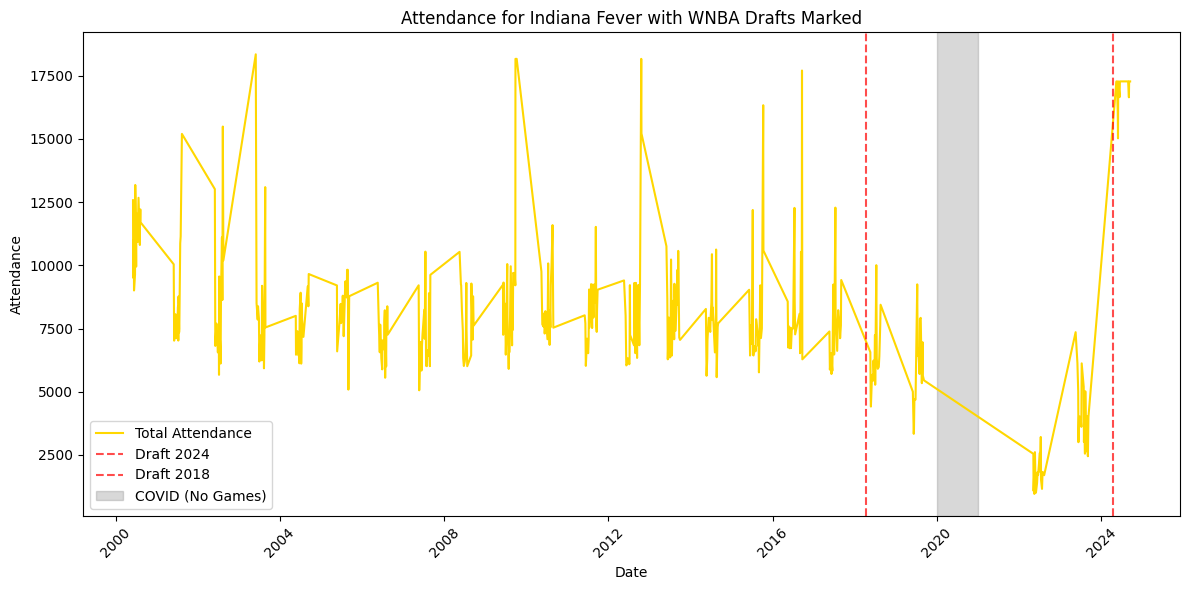

In [189]:
# Indiana Fever Visualization

plt.figure(figsize=(12, 6))

# Plot total attendance over time
sns.lineplot(x=ind_fever_games["Date"], y=ind_fever_games["Attendance"], label="Total Attendance", color="gold")

# Mark WNBA Draft dates with vertical dashed lines
for year, draft_date in draft_dates.items():
    plt.axvline(draft_date, linestyle="--", color="red", alpha=0.7, label=f"Draft {year}")

# Shade the COVID-affected period (2020) when no games were played
plt.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color="gray", alpha=0.3, label="COVID (No Games)")

# Titles and labels
plt.title("Attendance for Indiana Fever with WNBA Drafts Marked")
plt.xlabel("Date")
plt.ylabel("Attendance")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()